Loading grid...
Loading Philippine boundary...

Map saved to:
outputs\maps\philippines_spatial_grid.png


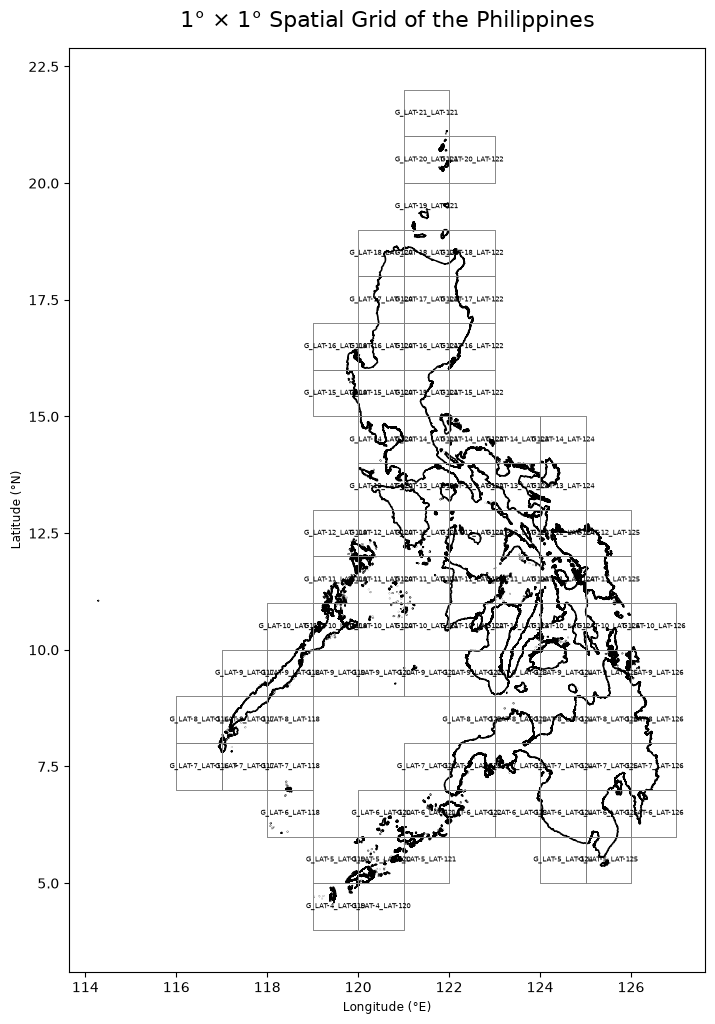

In [3]:
"""
map_grid.py

Visualize the generated Philippine 1° x 1° grid.
"""

from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt


# ============================================================
# FILES
# ============================================================

GRID_FILE = Path(
    "data/processed/philippines_grid.geojson"
)

BOUNDARY_FILE = Path(
    "data/boundaries/Philippines.shp/PH_Adm0_Country.shp.shp"
)

OUTPUT_DIR = Path(
    "outputs/maps"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# LOAD DATA
# ============================================================

print("Loading grid...")

grid = gpd.read_file(
    GRID_FILE
)

print("Loading Philippine boundary...")

philippines = gpd.read_file(
    BOUNDARY_FILE
)


# ============================================================
# ENSURE SAME CRS
# ============================================================

philippines = philippines.to_crs(
    grid.crs
)


# ============================================================
# CREATE MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 12)
)


# ------------------------------------------------------------
# Philippine boundary
# ------------------------------------------------------------

philippines.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

grid.plot(
    ax=ax,
    facecolor="none",
    edgecolor="gray",
    linewidth=0.5
)


# ============================================================
# ADD GRID LABELS
# ============================================================

for _, row in grid.iterrows():

    point = row.geometry.centroid

    ax.text(
        point.x,
        point.y,
        str(row["grid_id"]),
        fontsize=5,
        ha="center",
        va="center"
    )


# ============================================================
# MAP FORMATTING
# ============================================================

ax.set_title(
    "1° × 1° Spatial Grid of the Philippines",
    fontsize=16,
    pad=15
)

ax.set_xlabel(
    "Longitude (°E)"
)

ax.set_ylabel(
    "Latitude (°N)"
)

ax.set_aspect(
    "equal"
)

grid.plot(
    ax=ax,
    facecolor="none",
    edgecolor="gray",
    linewidth=0.5
)


# ============================================================
# SAVE
# ============================================================

output_file = (
    OUTPUT_DIR
    /
    "philippines_spatial_grid.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nMap saved to:\n{output_file}"
)

plt.show()


Map saved to:
outputs\maps\philippines_spatial_grid_numbers.png


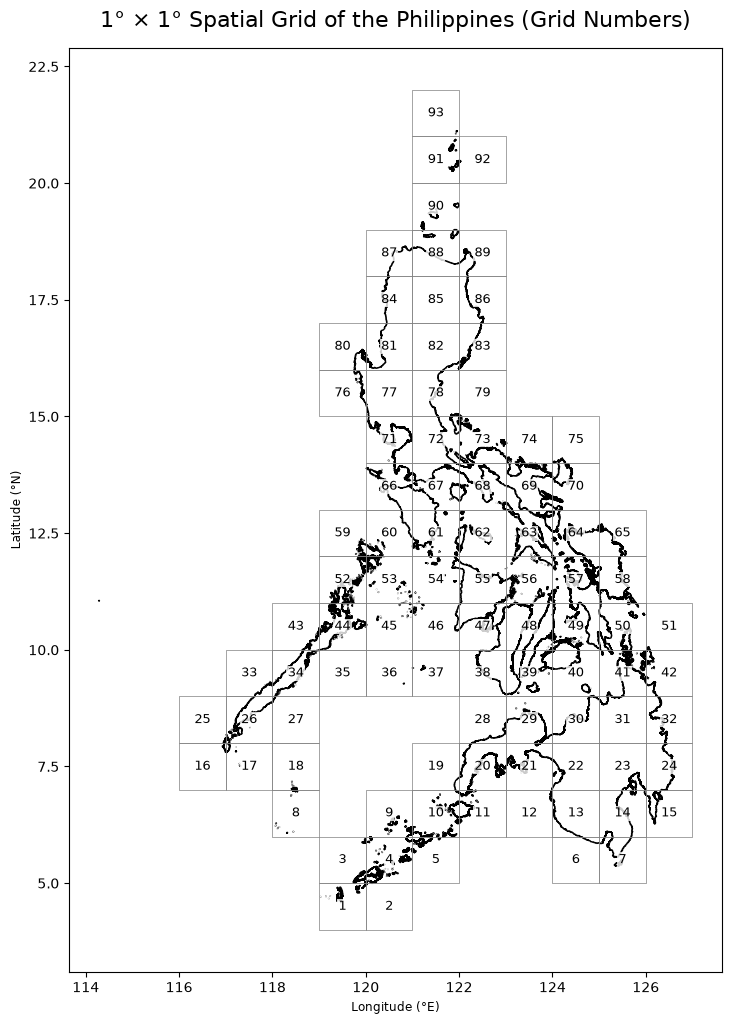

In [4]:
"""
Same map as above, labelled with grid_number instead of grid_id.

Uses `grid`, `philippines` and `OUTPUT_DIR` from the previous cell,
so run that cell first.
"""

# ============================================================
# CREATE MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 12)
)


# ------------------------------------------------------------
# Philippine boundary
# ------------------------------------------------------------

philippines.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

grid.plot(
    ax=ax,
    facecolor="none",
    edgecolor="gray",
    linewidth=0.5
)


# ============================================================
# ADD GRID NUMBER LABELS
# ============================================================

for _, row in grid.iterrows():

    point = row.geometry.centroid

    ax.text(
        point.x,
        point.y,
        str(row["grid_number"]),
        fontsize=9,
        ha="center",
        va="center",
        # White background keeps numbers readable over coastlines
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.8,
            pad=1
        )
    )


# ============================================================
# MAP FORMATTING
# ============================================================

ax.set_title(
    "1° × 1° Spatial Grid of the Philippines (Grid Numbers)",
    fontsize=16,
    pad=15
)

ax.set_xlabel(
    "Longitude (°E)"
)

ax.set_ylabel(
    "Latitude (°N)"
)

ax.set_aspect(
    "equal"
)


# ============================================================
# SAVE
# ============================================================

output_file = (
    OUTPUT_DIR
    /
    "philippines_spatial_grid_numbers.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nMap saved to:\n{output_file}"
)

plt.show()